# Table of Contents

- Logistic Regression in Depth
- Logistic Regression: Minimal Example
- K-Nearest Neighbors (KNN) Algorithm
- Decision Tree Algorithm
- Random Forest Algorithm
- Model Comparison
- Parameter vs Hyperparameter


Logistic Regression

#### 9. Real-World Applications

| Domain     | Problem              | Class 0      | Class 1        |
|------------|---------------------|--------------|----------------|
| Email      | Spam Detection      | Not Spam     | Spam           |
| Medical    | Disease Diagnosis   | Healthy      | Has Disease    |
| Finance    | Loan Default        | Will Repay   | Will Default   |
| Marketing  | Ad Click Prediction | No Click     | Click          |
| Retention  | Customer Churn      | Will Stay    | Will Churn     |
| Education  | Student Pass/Fail   | Fail         | Pass           |

### 10. Logistic Regression: Complete Workflow & Mathematical Summary

#### 1. The Prediction Process

i. **Input:** Features ($x_1, x_2, \dots, x_n$)

ii. **Linear Combination:**

>  $z = w_1x_1 + w_2x_2 + \dots + b$
*(Unbounded output from $-\infty$ to $+\infty$)*


iii. **Activation (Sigmoid):**

> $p = \sigma(z) = \frac{1}{1 + e^{-z}}$
*(Squashes output to a valid probability range $[0, 1]$)*

iv. **Thresholding:** Apply a decision threshold (typically $0.5$).

v. **Classification:**
>
* **Class 1 (Pass/Yes):** If $p \geq 0.5$
* **Class 0 (Fail/No):** If $p < 0.5$



---

#### 2. The Loss Function (Binary Cross-Entropy)

To train the model, we use **Cross-Entropy Loss** rather than MSE:


$$\text{Loss} = -\left[y \cdot \log(p) + (1 - y)\cdot \log(1 - p)\right]$$

**Why it works:**

* **Convexity:** Creates a single "bowl" shape (Global Minimum), making optimization reliable.
* **Sensitivity:** Penalizes wrong predictions exponentially, forcing the model to learn faster.
* **Gradient Flow:** Avoids the "flat" plateaus found in MSE for classification.

---

#### 3. Optimization Logic

The goal is to minimize the Cost Function $J(w,b)$ across $m$ examples:


$$J(w,b) = \frac{1}{m} \sum_{i=1}^{m} \text{Loss}_i$$

**Gradient Descent Step:**

* $w := w - \alpha \cdot \frac{\partial J}{\partial w}$
* $b := b - \alpha \cdot \frac{\partial J}{\partial b}$

---

#### 4. Key Insights

* **Interpretable:** Logistic regression estimates **probability**, not just hard labels.
* **Foundation:** This same logic (Linear $\rightarrow$ Activation $\rightarrow$ Loss) is the fundamental building block of **Neural Networks**.
* **Efficiency:** It is computationally "cheap" and performs exceptionally well on linearly separable data.

# **Logistic Regression using Scikit Learn**

In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Load Titanic dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

# Select features
df = df[["Pclass", "Sex", "Age", "Fare", "Survived"]]

# Handle missing values
df["Age"] = df["Age"].fillna(df["Age"].median())

# Encode categorical column
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

# Features and target
X = df.drop("Survived", axis=1)
y = df["Survived"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Feature scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# Model
model= LogisticRegression()

#Train
model.fit(X_train,y_train)

#predict
y_pred = model.predict(X_test)


#Probability for AUC
y_prob = model.predict_proba(X_test)[:, 1]


#Metrix
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC AUC  :", roc_auc_score(y_test, y_prob))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))


Accuracy : 0.7932960893854749
Precision: 0.7681159420289855
Recall   : 0.7162162162162162
F1 Score : 0.7412587412587412
ROC AUC  : 0.8745173745173744

Confusion Matrix:
 [[89 16]
 [21 53]]


# **K-Nearest Neighbors (KNN)**

# K-Nearest Neighbors (KNN)

KNN is one of the simplest machine learning algorithms.

The main idea:

> Look at the nearest data points, and predict based on what most of them are.

![](https://substackcdn.com/image/fetch/$s_!-q5-!,w_1456,c_limit,f_webp,q_auto:good,fl_progressive:steep/https%3A%2F%2Fsubstack-post-media.s3.amazonaws.com%2Fpublic%2Fimages%2Fd471b662-696e-4f70-b651-168958b6b39c_990x454.png)



#### **KNN Classification Pseudocode**
```

INPUT:
    Training data X
    Training labels Y
    New data point P
    Number of neighbors K

BEGIN

1. For each training point Xi in X:
    
    a. Calculate distance between P and Xi
    
    b. Store:
        (distance, corresponding label)

2. Sort all stored distances in ascending order

3. Select the first K nearest neighbors

4. Count how many times each class appears

5. Choose the class with highest count

6. Return predicted class

END
```


#### **Important Notes About KNN**

###### **1. KNN is a “Lazy Learner”**

KNN does not actually learn a mathematical model during training.

Most algorithms:

* learn patterns first
* then make predictions

But KNN simply:

* stores the training data
* waits until prediction time

That’s why it is called a **lazy learner**.

- Training is very fast
- Prediction can be slow

---

###### **2. KNN is Distance-Based**

KNN works by measuring distance between points.

Closer points are considered more similar.

Because of this, feature scaling is important.

Common distance metrics in KNN:

* **Euclidean Distance** → used most of the time
  Straight-line distance between two points.

 $ d = \sqrt{\sum_{i=1}^{n}(x_i-y_i)^2} $

* **Manhattan Distance**
  Distance measured by moving only horizontally and vertically (like city blocks).

 $ d = \sum_{i=1}^{n}|x_i-y_i|$

* **Minkowski Distance**
  Generalized version of Euclidean and Manhattan distance.

* **Hamming Distance**
  Used for categorical/binary data. Counts how many values differ.

* **Cosine Similarity / Cosine Distance**
  Measures angle similarity between vectors. Common in text/NLP tasks.

![](https://miro.medium.com/1*VteXrmdjFaJsqy4pz3JSTQ.png)

---

###### **3. KNN Has No Explicit Training Phase**

Unlike algorithms such as:

* Logistic Regression
* Decision Trees
* Neural Networks

KNN does not build equations or trees.

Training basically means:

> “Store the dataset.”

---

###### **4. Choice of K is Important**

* Small K → sensitive to noise (overfitting)
* Large K → too general (underfitting)

Typical values:

* K = 3
* K = 5
* K = 7

---

###### **5. KNN Can Be Slow for Large Datasets**

For every new prediction, KNN compares the new point with many existing points.

So:

* small dataset → fine
* huge dataset → slower predictions

---

###### **6. KNN Works for Both Classification and Regression**

* Classification → majority vote
* Regression → average of nearest values


In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Load Titanic dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

df.head()

# Select features
df = df[["Pclass", "Sex", "Age", "Fare", "Survived"]]

# Handle missing values
df["Age"] = df["Age"].fillna(df["Age"].median())

# Encode categorical column
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

# feature and terget
X= df.drop("Survived", axis=1)
y= df["Survived"]

# Train_test Split
X_train,X_test,y_train,y_test = train_test_split(
    X,y,
    test_size= 0.2,
    random_state=42
)

# Feature scaling (important for KNN)
scaler= StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# KNN model
model = KNeighborsClassifier(n_neighbors=5)

# Train
model.fit(X_train,y_train)


#Prediction
y_pred= model.predict(X_test)

#Probability for AUC
y_prob = model.predict_proba(X_test)[:, 1]

# Metrics
print("Accuracy :", accuracy_score(y_test, y_pred))
print(" precision :", precision_score(y_test, y_pred))
print("recall :", recall_score(y_test, y_pred))
print("f1_score:", f1_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_prob))

print("\nconfusion_matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy : 0.8212290502793296
 precision : 0.8181818181818182
recall : 0.7297297297297297
f1_score: 0.7714285714285715
ROC AUC: 0.865057915057915

confusion_matrix:
 [[93 12]
 [20 54]]


   KNN OPTIMIZATION REPORT
Analysis range: K=1 to K=30
Minimum Error Rate: 0.1788

Conclusion: We will use K = 5,
because it gives us the least loss and the highest accuracy.
This point represents the optimal balance between Bias and Variance.


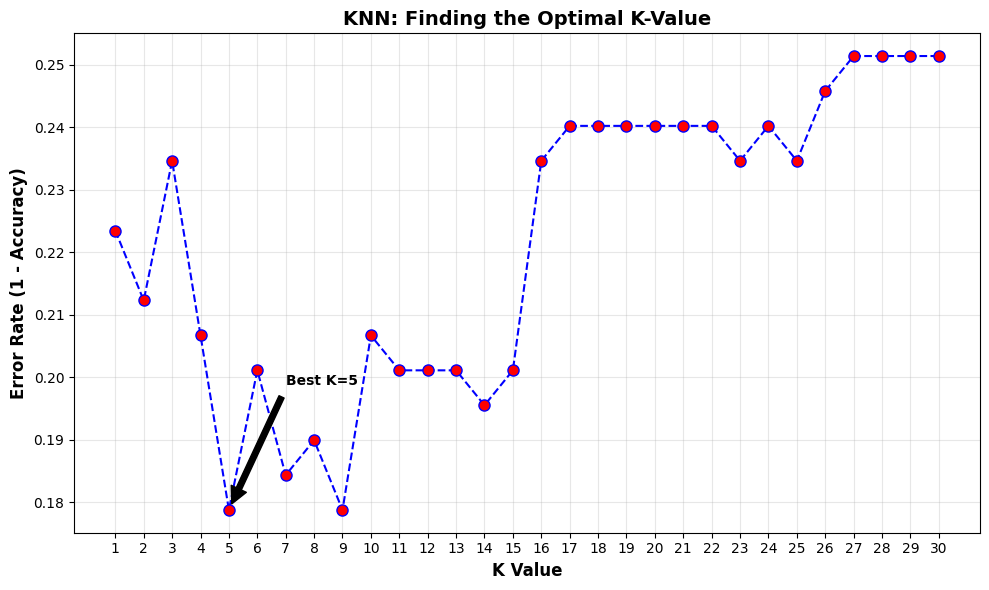

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# --- Formatting Constants ---
BOLD   = '\033[1m'
RED    = '\033[91m'
GREEN  = '\033[92m'
BLUE   = '\033[94m'
PURPLE = '\033[95m'
END    = '\033[0m'


# 1. Load and Clean Dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

df = df[["Pclass", "Sex", "Age", "Fare", "Survived"]]
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

X = df.drop("Survived", axis=1)
y = df["Survived"]

# 2. Split and Scale
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 3. Find optimal K
k_values = range(1, 31)
errors = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    errors.append(1 - acc)

# Identify the best K programmatically
min_error = min(errors)
best_k = k_values[np.argmin(errors)]

# 4. Styled Console Output (Print first for stability)
print(f"{BOLD}{BLUE}===================================================={END}")
print(f"{BOLD}   KNN OPTIMIZATION REPORT{END}")
print(f"{BOLD}{BLUE}===================================================={END}")
print(f"Analysis range: {BOLD}K=1 to K=30{END}")
print(f"Minimum Error Rate: {GREEN}{min_error:.4f}{END}")
print(f"\nConclusion: We will use {BOLD}{RED}K = {best_k}{END},")
print(f"because it gives us the {BOLD}least loss{END} and the {BOLD}highest accuracy{END}.")
print(f"This point represents the optimal balance between {PURPLE}Bias and Variance{END}.")
print(f"{BOLD}{BLUE}===================================================={END}")

# 5. Plot Error vs K
plt.figure(figsize=(10, 6))
plt.plot(k_values, errors, color='blue', linestyle='dashed', marker='o',
         markerfacecolor='red', markersize=8)

# Highlight the best K point on the plot
plt.annotate(f'Best K={best_k}', xy=(best_k, min_error), xytext=(best_k+2, min_error+0.02),
             arrowprops=dict(facecolor='black', shrink=0.05),
             fontweight='bold')

plt.xlabel("K Value", fontsize=12, fontweight='bold')
plt.ylabel("Error Rate (1 - Accuracy)", fontsize=12, fontweight='bold')
plt.title("KNN: Finding the Optimal K-Value", fontsize=14, fontweight='bold')
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Decision Tree Classifier


![](https://blogger.googleusercontent.com/img/b/R29vZ2xl/AVvXsEjq7iPacW7sZedJsEr1Uo3GluS3Qa0Lort9nmtJ1D4YaE9BuHctetFaS63dSPlYrd6N-OR_6uhyqESSY57f_fLQtEZN9VAcFf9GpPPsS_tS96SueadV_DTisQEGly8JMRTuF2XfVxU1Tott/s640/1.PNG)



#### 🌳 Decision Tree

A Decision Tree is a supervised machine learning algorithm used for **classification and regression**. It works like a flowchart of decisions. A Decision Tree makes predictions by repeatedly splitting data using the best feature until it reaches a final decision.

---

#### 🧠 Basic Idea

> “Ask a series of yes/no questions to reach a decision.”

Example:

* Is age > 18?
* Is income > 50K?
* Is credit score high?

Finally, you reach a prediction.

---

#### 🌳 How It Works

1. Start with the full dataset (root node)
2. Find the best feature to split the data
3. Split data into branches
4. Repeat recursively
5. Stop when:

   * data is pure (only one class)
   * or max depth is reached

---

#### 🔀 Example Structure

```
            Age > 30?
           /        \
        Yes          No
       /              \
  Income > 50K?     Class B
     /     \
 Class A   Class B
```

![](https://dataaspirant.com/wp-content/uploads/2017/01/B03905_05_01-compressor.png)




---

#### 📊 Splitting Criteria

Decision trees choose the best split using:

**1. Gini Impurity**


Measures how “mixed” a node is.

$$
Gini = 1 - \sum p_i^2
$$

* 0 → pure node
* higher → more impurity

---

**2. Entropy (Information Gain)**

Measures disorder in data.

$$
Entropy = -\sum p_i \log_2(p_i)
$$

Model tries to **reduce entropy** after split.

---

#### 🌱 Key Terms

**Root Node**

* First split of the tree

**Leaf Node**

* Final prediction (no more splits)

**Internal Node**

* Decision point in the tree

**Branch**

* Path from root to leaf

---

#### Advantages

- Easy to understand
- Works with numeric + categorical data
- No feature scaling needed
- Handles nonlinear relationships

---

#### Disadvantages

- Overfitting (very common)
- Sensitive to small data changes
- Can become very complex

---

#### Decision Tree Training

Decision Tree does have a training phase. During training, it learns how to split the data into smaller and smaller groups by choosing the best features and split points. The goal is to create rules that separate the classes as clearly as possible.

**What happens during training:**
- Tries different feature splits (e.g., Age < 30, Fare < 50)
- Chooses the best split using Gini impurity or Entropy
- Repeats splitting recursively for each branch
- Stops when nodes are pure or limits (like max depth) are reached


In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)


# Load Titanic dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

df.head()

# Select features
df = df[["Pclass", "Sex", "Age", "Fare", "Survived"]]

# Handle missing values
df["Age"] = df["Age"].fillna(df["Age"].median())

# Encode categorical column
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

# feature and terget
X= df.drop("Survived", axis=1)
y= df["Survived"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# ⚠️ Note: Scaling is NOT required for Decision Trees
# Keeping it optional here (you can remove it safely)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# Model
model = DecisionTreeClassifier(
    max_depth= 5,
    random_state=42
)

# Train
model.fit(X_train, y_train)


#Prediction
y_pred = model.predict(X_test)

# probability for AUC
y_prob = model.predict_proba(X_test)[:, 1]

# Metrics
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC AUC  :", roc_auc_score(y_test, y_prob))

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))


Accuracy : 0.8044692737430168
Precision: 0.8305084745762712
Recall   : 0.6621621621621622
F1 Score : 0.7368421052631579
ROC AUC  : 0.861003861003861

Confusion Matrix:
 [[95 10]
 [25 49]]


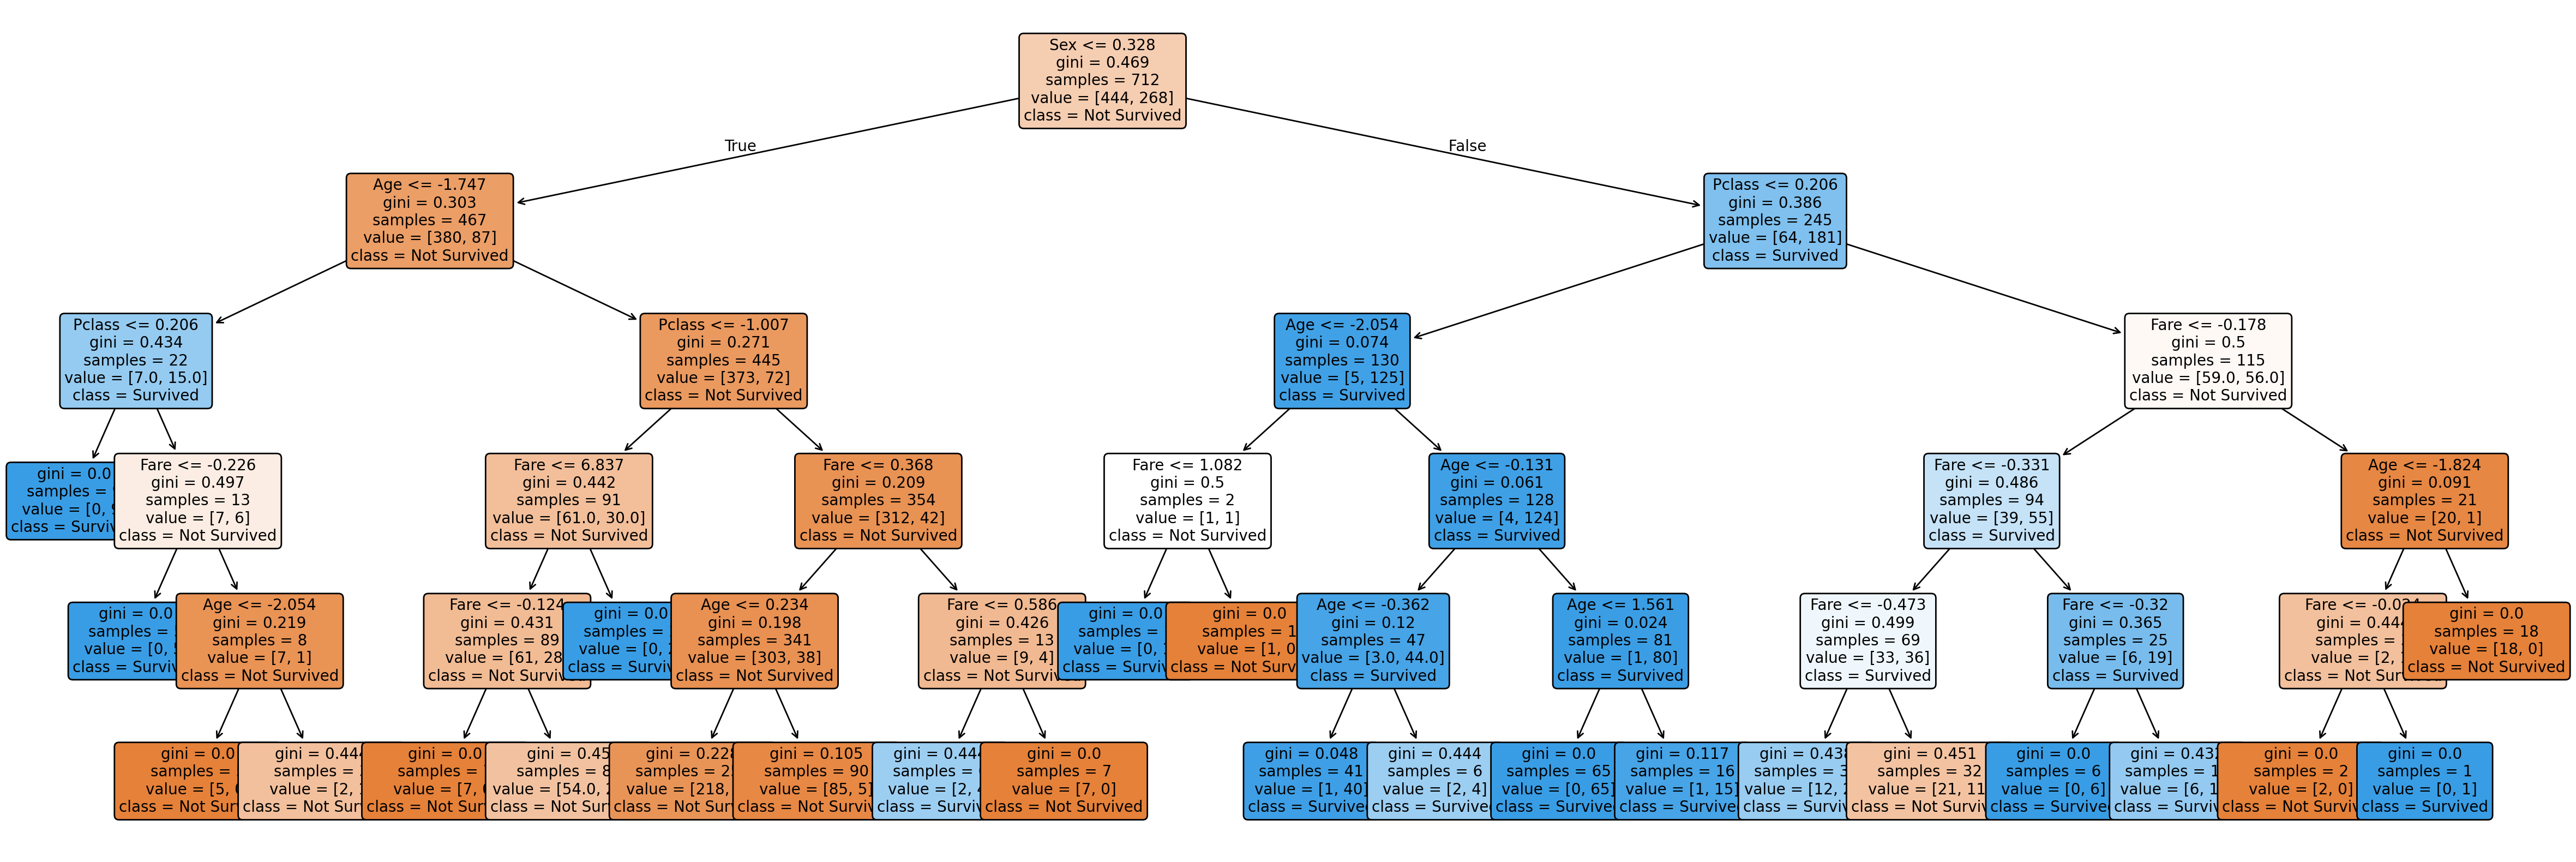

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(30,10), dpi=200)

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Not Survived", "Survived"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.show()

# Random Forest Algorithm

Random Forest is an **ensemble learning algorithm** used for classification and regression. It combines multiple Decision Trees to make more accurate and stable predictions.

![](https://media.geeksforgeeks.org/wp-content/uploads/20251216121929631349/random_forest_algorithm.webp)


---

#### 🧠 Basic Idea

> “Many weak decision trees together make a strong model.”

Instead of relying on one tree, Random Forest builds many trees and takes a **majority vote (classification)** or **average (regression)**.

---

#### 🌳 How It Works

* Create multiple Decision Trees
* Each tree is trained on a **random subset of data**
* Each split considers a **random subset of features**
* Combine outputs of all trees

![](https://media.geeksforgeeks.org/wp-content/uploads/20250627112620729188/tree_1.webp)


---

#### 🗳️ Final Prediction

**Classification:**

* Each tree votes
* Majority vote wins

**Regression:**

* Take average of all tree outputs

---

#### 🔀 Why “Random”?

Randomness comes from:

* **Data sampling (Bootstrap sampling)**
* **Feature selection randomness**

This reduces overfitting.

---

#### 🌟 Key Idea: Bagging

Random Forest uses **Bagging (Bootstrap Aggregation)**:

* Train multiple models independently
* Combine results

---

#### ⚖️ Advantages

- Reduces overfitting (better than single tree)
- Works well on large datasets
- Handles missing values well
- No need for feature scaling

---

#### ❌ Disadvantages

- Slower than single Decision Tree
- Hard to interpret (black box model)
- Uses more memory

---

#### 🧾 One-line Summary

> Random Forest is a collection of many Decision Trees that work together to give more accurate and stable predictions.


In [7]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Load dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

df.head()

#select feature
df= df[["Pclass","Sex","Age","Fare","Survived"]]

# Handle missing values
df["Age"] = df["Age"].fillna(df["Age"].median())

# Encode categorical column
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

# feature and target
X= df.drop("Survived", axis=1)
y= df["Survived"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.2, random_state=42
)

# ⚠️ Scaling not required for Random Forest (but kept for consistency)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test= scaler.transform(X_test)


# Model
model = RandomForestClassifier(
    n_estimators= 100,
    max_depth= 5,
    random_state = 42
)

# Train
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)


# Probability
y_prob= model.predict_proba(X_test)[:, 1]



# Metrics
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC AUC  :", roc_auc_score(y_test, y_prob))

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy : 0.8100558659217877
Precision: 0.8333333333333334
Recall   : 0.6756756756756757
F1 Score : 0.746268656716418
ROC AUC  : 0.8751608751608752

Confusion Matrix:
 [[95 10]
 [24 50]]


# Model Comparison

Model comparison is used to evaluate different machine learning algorithms on the same dataset using a consistent metric (like accuracy, F1-score, etc.). However, the results do not always mean that one model is universally better than the others. A model that performs best on one dataset may perform worse on another due to differences in data distribution, noise, feature relationships, and hyperparameter settings.

So, model comparison should be seen as a **decision-making tool**, not a final judgment. It helps us understand which model is more suitable for a specific problem and helps guide further tuning and experimentation.

---

#### **Key points:**

* Results depend on dataset, not just the algorithm
* No single model is best for all problems (“No Free Lunch Theorem”)
* Performance changes with hyperparameters and feature engineering
* Evaluation metric choice (accuracy, F1, etc.) affects comparison
* Best model = best for *this specific problem*, not always globally best


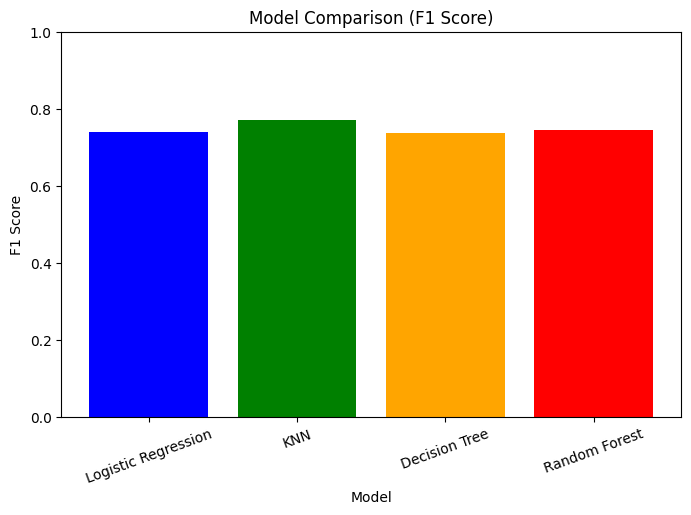

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Load dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

df.head()

df = df[["Pclass", "Sex", "Age", "Fare", "Survived"]]
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})


X = df.drop("Survived", axis=1)
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
}

colors = ["blue", "green", "orange", "red"]

f1_scores = []

for name, model in models.items():
    if name in ["Logistic Regression", "KNN"]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    f1_scores.append(f1_score(y_test, y_pred))

# Plotting code (now correctly unindented outside of the loop)
plt.figure(figsize=(8,5))
plt.bar(models.keys(), f1_scores, color=colors)
plt.xlabel("Model")
plt.ylabel("F1 Score")
plt.title("Model Comparison (F1 Score)")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.show()

# ⚙️ Parameters vs Hyperparameters

## 🧠 Parameters

These are **learned from data during training**.

* The model automatically learns them
* You don’t set them manually

#### Examples:

* Logistic Regression → weights (w), bias (b)
* Decision Tree → split rules
* Random Forest → tree structures

---

## ⚙️ Hyperparameters

These are **set by you before training**.

* Control how the model learns
* Need tuning for best performance

#### Examples (important ones):

**🌲 Random Forest**

* `n_estimators` → number of trees
* `max_depth` → depth of each tree
* `min_samples_split` → minimum samples to split a node

**🌳 Decision Tree**

* `max_depth`
* `min_samples_leaf`

**📍 KNN**

* `n_neighbors (K)`
* distance metric

**📈 Logistic Regression**

* `C` → regularization strength
* `penalty`

---

## 🔍 Hyperparameter Tuning Methods

We need hyperparameter tuning because machine learning models don’t automatically know the best settings to learn from data. Hyperparameters control how a model behaves, and different values can lead to very different performance. So tuning is basically the process of finding the best configuration for your model on your data. There is no universal best setting.
What works for Titanic may not work for another dataset.

#### 1. Grid Search CV

* Tries **all combinations**
* Accurate but slow

#### 2. Random Search CV

* Tries **random combinations**
* Faster and good for large search spaces

![](https://miro.medium.com/0*QKZG5I3autl1HvlY.png)

---

## 🌲 Random Forest Example (GridSearchCV + RandomizedSearchCV)

#### 📌 Code Setup

```python id="rf_tuning_01"
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

# Load dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

df = df[["Pclass", "Sex", "Age", "Fare", "Survived"]]
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

X = df.drop("Survived", axis=1)
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
```

---

#### 🌳 1. Grid Search CV

```python id="grid_rf"
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 10],
    "min_samples_split": [2, 5, 10]
}

rf = RandomForestClassifier(random_state=42)

grid = GridSearchCV(
    rf,
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Params (GridSearch):", grid.best_params_)

best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

print("F1 Score:", f1_score(y_test, y_pred))
```

---

#### 🎲 2. Random Search CV

```python id="random_rf"
from scipy.stats import randint

param_dist = {
    "n_estimators": randint(50, 300),
    "max_depth": randint(2, 15),
    "min_samples_split": randint(2, 20)
}

rf = RandomForestClassifier(random_state=42)

random_search = RandomizedSearchCV(
    rf,
    param_distributions=param_dist,
    n_iter=20,
    cv=5,
    scoring="f1",
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

print("Best Params (RandomSearch):", random_search.best_params_)

best_model = random_search.best_estimator_

y_pred = best_model.predict(X_test)

print("F1 Score:", f1_score(y_test, y_pred))
```

---

## ⚡ Key Difference

| Method        | Idea                   | Speed  | Accuracy |
| ------------- | ---------------------- | ------ | -------- |
| Grid Search   | tries all combinations | ❌ slow | ✅ best   |
| Random Search | tries random combos    | ✅ fast | ✅ good   |

---

## 🧾 One-line Summary

> Parameters are learned by the model, while hyperparameters are set by us and tuned using Grid Search or Random Search to improve performance.
